# 04 - Unfavorable-outcome modeling
Rahel Genene and Hanna Getachw - DBU Data Science internship, Ministry of Health, Ethiopia

Target: **unfavorable outcome** = patient status `died` or `inactive_or_lost` (lost to follow-up), versus `active` (retained in care). This is the broader definition used for the dashboard, built after the death-only target in `03_ML_modeling_mortality.ipynb` proved too rare (about 4.4% of patients).

Inputs: `output/01_pre_processing/data/` (from `01_pre_processing.ipynb`). Outputs: `output/04_ML_modeling_unfavorable_outcome/`.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

ROOT = Path('..').resolve()
IN = ROOT / 'output' / '01_pre_processing' / 'data'
OUT = ROOT / 'output' / '04_ML_modeling_unfavorable_outcome'
for sub in ('data', 'figures', 'tables', 'models'):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

df = pd.read_csv(IN / 'CEM_final_preprocessed.csv', low_memory=False)
labs = pd.read_csv(IN / 'lab_events_clean.csv', low_memory=False)
labs['test_date'] = pd.to_datetime(labs['test_date'], errors='coerce')
print('patients:', df.shape, ' lab events:', labs.shape)
print(df['patient_status'].value_counts().to_string())

patients: (2478, 877)  lab events: (5276, 8)
patient_status
active              1469
inactive_or_lost     899
died                 110


## 1. Build the modeling table
Same baseline predictors as the mortality model; only the target changes.

In [2]:
def clean_stage(v):
    if pd.isna(v): return np.nan
    s = str(v).strip().upper()
    roman = {'I': 1, 'II': 2, 'III': 3, 'IV': 4}
    if s in roman: return roman[s]
    if s in {'1', '2', '3', '4'}: return int(s)
    return np.nan

tbl = df[['patient_id', 'patient_status']].copy()
tbl['unfavorable'] = tbl['patient_status'].isin(['died', 'inactive_or_lost']).astype(int)

demo = df[['patient_id', 'age_clean', 'sex', 'health_facility', 'subcity_clean']].copy()
demo['baseline_who_stage'] = df['who_hiv_stage_at_this_scre'].apply(clean_stage)
vitals = df[['patient_id', 'weight_clean', 'height_clean', 'bmi_recalculated']]

cd4 = (labs[(labs['test_name'] == 'CD4') & (labs['status'] == 'numeric')]
       .sort_values('test_date').groupby('patient_id')['value'].first().rename('baseline_cd4').reset_index())
vl = (labs[labs['test_name'] == 'ViralLoad']
      .sort_values('test_date').groupby('patient_id')['status'].first().rename('baseline_vl_status').reset_index())
visits = (labs.dropna(subset=['test_date']).groupby('patient_id')
          .agg(n_lab_events=('test_date', 'count'),
               days_on_treatment=('test_date', lambda x: (x.max() - x.min()).days)).reset_index())

tbl = (tbl.merge(demo, on='patient_id', how='left').merge(vitals, on='patient_id', how='left')
          .merge(cd4, on='patient_id', how='left').merge(vl, on='patient_id', how='left')
          .merge(visits, on='patient_id', how='left'))

# group subcities with fewer than 10 patients into "Other"
counts = tbl['subcity_clean'].value_counts()
tbl['subcity_grouped'] = tbl['subcity_clean'].where(tbl['subcity_clean'].isin(counts[counts >= 10].index), 'Other')

tbl.to_csv(OUT / 'data' / 'unfavorable_outcome_modeling_table.csv', index=False)
print('table shape:', tbl.shape)
print(f"unfavorable-outcome rate: {tbl['unfavorable'].mean()*100:.2f}%")

table shape: (2478, 16)
unfavorable-outcome rate: 40.72%


## 2. Prepare features

In [3]:
numeric_feats = ['age_clean', 'weight_clean', 'height_clean', 'bmi_recalculated',
                 'baseline_who_stage', 'baseline_cd4', 'n_lab_events', 'days_on_treatment']
categorical_feats = ['sex', 'baseline_vl_status', 'subcity_grouped']

m = tbl.copy()
for c in numeric_feats:
    m[c] = m[c].fillna(m[c].median())
encoders = {}
for c in categorical_feats:
    m[c] = m[c].fillna('Unknown').astype(str)
    encoders[c] = LabelEncoder().fit(m[c])
    m[c + '_enc'] = encoders[c].transform(m[c])

feature_cols = numeric_feats + [c + '_enc' for c in categorical_feats]
X, y = m[feature_cols], m['unfavorable']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('train', X_train.shape, f'{y_train.mean()*100:.1f}% unfavorable | test', X_test.shape, f'{y_test.mean()*100:.1f}%')

train (1982, 11) 40.7% unfavorable | test (496, 11) 40.7%


## 3. Train and compare four models

In [4]:
models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=6, class_weight='balanced', random_state=42),
    'SVM': SVC(kernel='rbf', probability=True, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42),
}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
rows, fitted, probas = [], {}, {}
for name, mdl in models.items():
    mdl.fit(X_train, y_train)
    pred = mdl.predict(X_test); proba = mdl.predict_proba(X_test)[:, 1]
    fitted[name], probas[name] = mdl, proba
    cvs = cross_val_score(mdl, X, y, cv=cv, scoring='roc_auc')
    rows.append({'Model': name, 'CV_ROC_AUC_mean': cvs.mean(), 'CV_ROC_AUC_std': cvs.std(),
                 'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, zero_division=0),
                 'Recall': recall_score(y_test, pred, zero_division=0), 'F1': f1_score(y_test, pred, zero_division=0),
                 'Test_ROC_AUC': roc_auc_score(y_test, proba)})
results = pd.DataFrame(rows).round(3)
results.to_csv(OUT / 'tables' / 'model_comparison_unfavorable_outcome.csv', index=False)
results

,Model,CV_ROC_AUC_mean,CV_ROC_AUC_std,Accuracy,Precision,Recall,F1,Test_ROC_AUC
0,Decision Tree,0.685,0.034,0.615,0.524,0.604,0.561,0.643
1,Random Forest,0.719,0.022,0.639,0.551,0.619,0.583,0.687
2,SVM,0.562,0.016,0.544,0.442,0.455,0.449,0.554
3,Gradient Boosting,0.709,0.011,0.645,0.571,0.520,0.544,0.657


## 4. Best model: confusion matrix, ROC curves, feature importance

Best model by cross-validated ROC-AUC: Random Forest


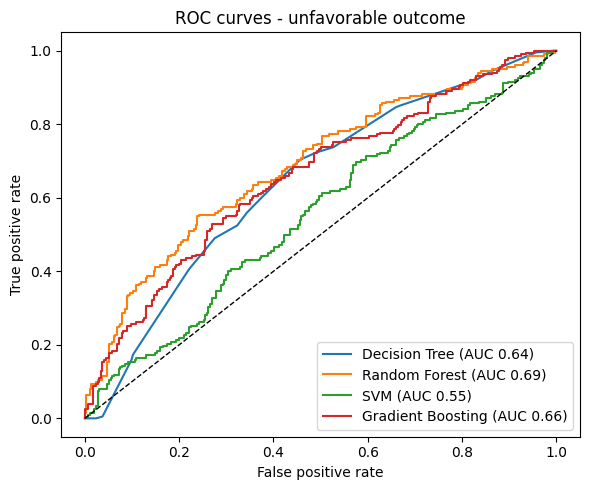

,Predicted: favorable,Predicted: unfavorable
Actual: favorable,192,102
Actual: unfavorable,77,125


In [5]:
best = results.sort_values('CV_ROC_AUC_mean', ascending=False).iloc[0]['Model']
print('Best model by cross-validated ROC-AUC:', best)

fig, ax = plt.subplots(figsize=(6, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, label=f'{name} (AUC {roc_auc_score(y_test, p):.2f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate')
ax.set_title('ROC curves - unfavorable outcome'); ax.legend(loc='lower right')
plt.tight_layout(); plt.savefig(OUT / 'figures' / 'roc_curves.png', dpi=150); plt.show()

cm = confusion_matrix(y_test, fitted[best].predict(X_test))
cm_df = pd.DataFrame(cm, index=['Actual: favorable', 'Actual: unfavorable'],
                     columns=['Predicted: favorable', 'Predicted: unfavorable'])
cm_df.to_csv(OUT / 'tables' / 'confusion_matrix_best_model.csv')
cm_df

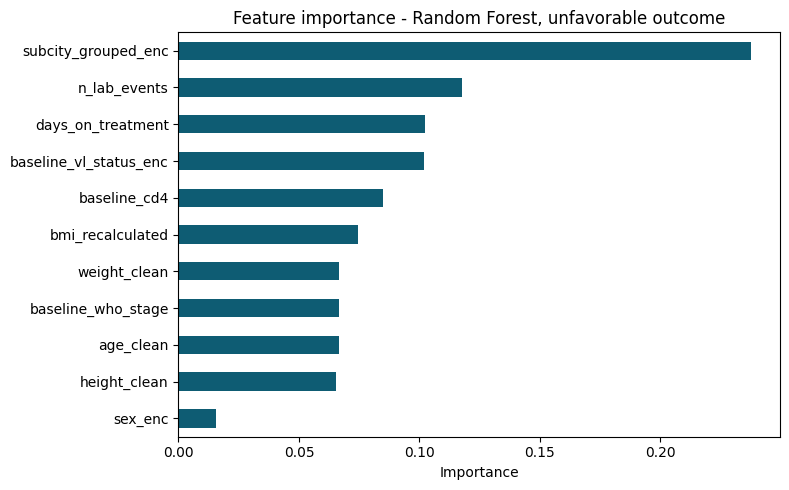

subcity_grouped_enc       0.238
n_lab_events              0.118
days_on_treatment         0.102
baseline_vl_status_enc    0.102
baseline_cd4              0.085
bmi_recalculated          0.075
weight_clean              0.067
baseline_who_stage        0.067
age_clean                 0.067
height_clean              0.065
sex_enc                   0.016
dtype: float64

In [6]:
rf = fitted['Random Forest']
imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
imp.rename('importance').to_csv(OUT / 'tables' / 'feature_importance_random_forest.csv')
fig, ax = plt.subplots(figsize=(8, 5))
imp.plot(kind='barh', color='#0e5c73', ax=ax); ax.invert_yaxis()
ax.set_title('Feature importance - Random Forest, unfavorable outcome'); ax.set_xlabel('Importance')
plt.tight_layout(); plt.savefig(OUT / 'figures' / 'feature_importance.png', dpi=150); plt.show()
imp.round(3)

## 5. Save the model

In [7]:
joblib.dump(fitted['Random Forest'], OUT / 'models' / 'unfavorable_outcome_rf_model.pkl')
joblib.dump(encoders, OUT / 'models' / 'unfavorable_outcome_encoders.pkl')
print('Saved model and encoders to', OUT / 'models')

Saved model and encoders to /home/claude/work/pkg/CEM_Project/output/04_ML_modeling_unfavorable_outcome/models


## Notes
- Metrics come from a single 80/20 stratified split plus 5-fold cross-validation, on one dataset from one program; they have not been validated on a different period or facility set.
- This notebook rebuilds the workflow from the saved pre-processing outputs; small differences from the figures quoted in the report (which came from the original run) are expected.
- The R Shiny dashboard (`dashboard/app.R`) re-implements these four models in R; live version: https://rahelgenene.shinyapps.io/cem_deploy/